In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

df = pd.read_csv("instagram_data.csv")
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print(df.head())
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").copy()
df["Engagement"] = df[["Likes", "Comments", "Shares", "Saves"]].sum(axis=1)
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()


(101, 10)
PostID         str
Date           str
PostType       str
Likes        int64
Comments     int64
Shares       int64
Saves        int64
Reach        int64
Followers    int64
Hashtags     int64
dtype: object
PostID       0
Date         0
PostType     0
Likes        0
Comments     0
Shares       0
Saves        0
Reach        0
Followers    0
Hashtags     0
dtype: int64
   PostID        Date  PostType  Likes  Comments  Shares  Saves  Reach  \
0  IG0001  2026-01-03     Photo     23         0       2      1    405   
1  IG0002  2026-01-06      Reel     76         2       8      8    735   
2  IG0003  2026-01-09      Reel     48         1       5      6    648   
3  IG0004  2026-01-12  Carousel     45         2       4      4    642   
4  IG0005  2026-01-15     Photo     54         2       2      2    476   

   Followers  Hashtags  
0        935        12  
1        906         0  
2        915        10  
3        964         0  
4        904         0  


In [6]:
df.head()

,PostID,Date,PostType,Likes,Comments,Shares,Saves,Reach,Followers,Hashtags,Engagement,Month
0,IG0001,2026-01-03,Photo,23,0,2,1,405,935,12,26,2026-01-01
1,IG0002,2026-01-06,Reel,76,2,8,8,735,906,0,94,2026-01-01
2,IG0003,2026-01-09,Reel,48,1,5,6,648,915,10,60,2026-01-01
3,IG0004,2026-01-12,Carousel,45,2,4,4,642,964,0,55,2026-01-01
4,IG0005,2026-01-15,Photo,54,2,2,2,476,904,0,60,2026-01-01


       Month  MeanEngagement  TotalEngagement  PostCount
0 2026-01-01       54.400000              544         10
1 2026-02-01       54.666667              492          9
2 2026-03-01       84.181818              926         11
3 2026-04-01      120.000000             1200         10
4 2026-05-01       79.900000              799         10
5 2026-06-01       77.000000              770         10
6 2026-07-01       99.200000              992         10
7 2026-08-01      122.727273             1350         11
8 2026-09-01      106.000000             1060         10
9 2026-10-01      100.300000             1003         10


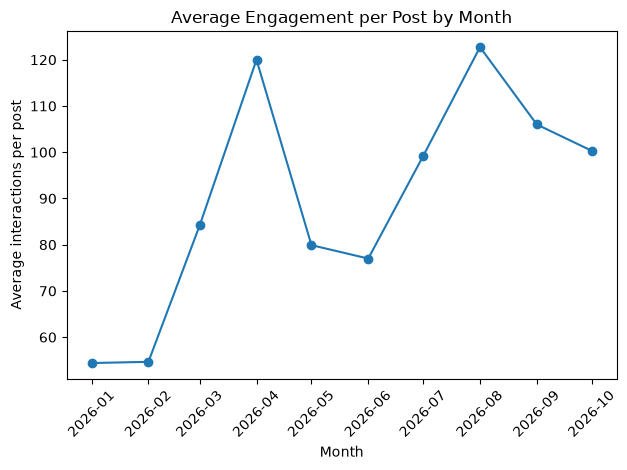

In [7]:
monthly = df.groupby("Month").agg(
    MeanEngagement=("Engagement", "mean"),
    TotalEngagement=("Engagement", "sum"),
    PostCount=("PostID", "count")
).reset_index()
print(monthly)
plt.plot(monthly["Month"], monthly["MeanEngagement"], marker="o")
plt.title("Average Engagement per Post by Month")
plt.xlabel("Month"); plt.ylabel("Average interactions per post")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()


       Month  MeanEngagement  PercentChange  MovingAverage3
0 2026-01-01       54.400000            NaN             NaN
1 2026-02-01       54.666667       0.490196             NaN
2 2026-03-01       84.181818      53.991131       64.416162
3 2026-04-01      120.000000      42.548596       86.282828
4 2026-05-01       79.900000     -33.416667       94.693939
5 2026-06-01       77.000000      -3.629537       92.300000
6 2026-07-01       99.200000      28.831169       85.366667
7 2026-08-01      122.727273      23.717009       99.642424
8 2026-09-01      106.000000     -13.629630      109.309091
9 2026-10-01      100.300000      -5.377358      109.675758


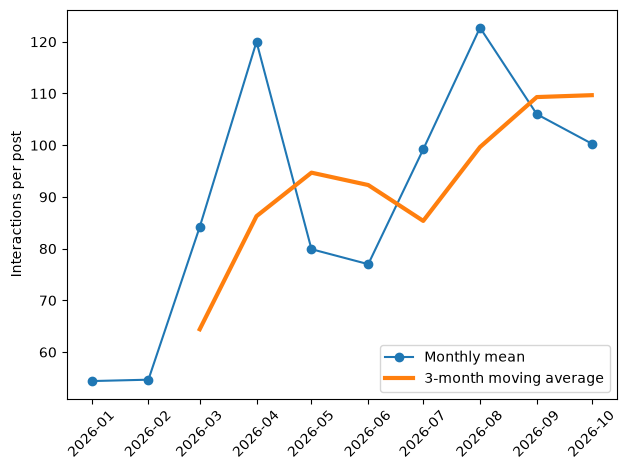

In [8]:
monthly["PercentChange"] = monthly["MeanEngagement"].pct_change() * 100
monthly["MovingAverage3"] = monthly["MeanEngagement"].rolling(3).mean()
print(monthly[["Month", "MeanEngagement", "PercentChange", "MovingAverage3"]])
plt.plot(monthly["Month"], monthly["MeanEngagement"], marker="o", label="Monthly mean")
plt.plot(monthly["Month"], monthly["MovingAverage3"], linewidth=3, label="3-month moving average")
plt.xticks(rotation=45); plt.ylabel("Interactions per post")
plt.legend(); plt.tight_layout(); plt.show()


Intercept     59.842222
MonthIndex     5.453701
dtype: float64
R-squared: 0.468
   MonthIndex   Predicted
0          11  119.832929
1          12  125.286630


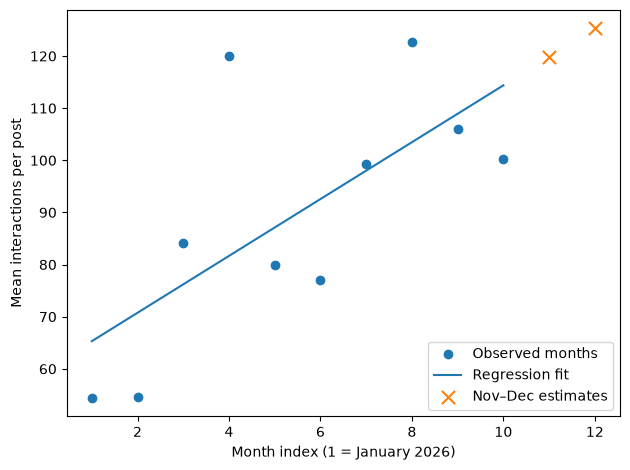

In [9]:
monthly["MonthIndex"] = range(1, len(monthly) + 1)
model = smf.ols("MeanEngagement ~ MonthIndex", data=monthly).fit()
print(model.params)
print("R-squared:", round(model.rsquared, 3))
monthly["Fitted"] = model.predict(monthly)
future = pd.DataFrame({"MonthIndex": [11, 12]})
future["Predicted"] = model.predict(future)
print(future)
plt.scatter(monthly["MonthIndex"], monthly["MeanEngagement"], label="Observed months")
plt.plot(monthly["MonthIndex"], monthly["Fitted"], label="Regression fit")
plt.scatter(future["MonthIndex"], future["Predicted"], marker="x", s=90, label="Nov–Dec estimates")
plt.xlabel("Month index (1 = January 2026)")
plt.ylabel("Mean interactions per post")
plt.legend(); plt.tight_layout(); plt.show()


In-sample MAE: 13.35


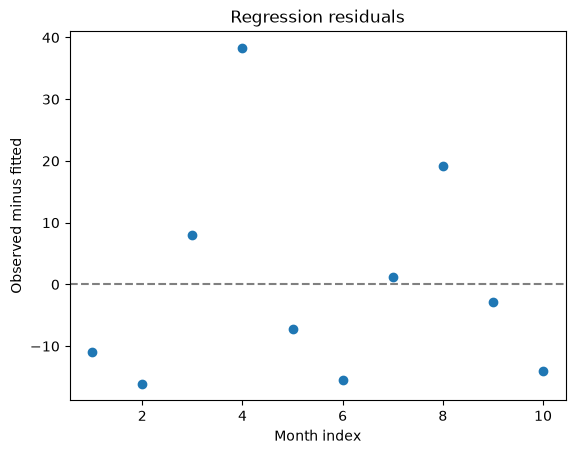

In [10]:
monthly["Residual"] = monthly["MeanEngagement"] - monthly["Fitted"]
mae = monthly["Residual"].abs().mean()
print("In-sample MAE:", round(mae, 2))
plt.axhline(0, color="gray", linestyle="--")
plt.scatter(monthly["MonthIndex"], monthly["Residual"])
plt.xlabel("Month index"); plt.ylabel("Observed minus fitted")
plt.title("Regression residuals"); plt.show()
